In [1]:
import datetime
import functools
import math
from typing import Callable

from line_profiler import profile
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import jax.scipy as jsp
import numpy as np
import pandas as pd
import matplotlib
from matplotlib import pyplot as plt
import scipy as scp

%matplotlib inline
%load_ext line_profiler

In [2]:
df = pd.read_csv("sotonmet.txt", parse_dates=["Reading Date and Time (ISO)"])
t = df["Reading Date and Time (ISO)"]
t = (t - t.min()).dt.total_seconds() / 86400
t = t.to_numpy()
f = df["Tide height (m)"].to_numpy()
y = df["True tide height (m)"].to_numpy()
df.head()

,Update Date and Time (ISO),Update Duration (ms),Reading Date and Time (ISO),Air pressure (mb),Air temperature (C),Tide height (m),Wind direction (deg),Wind gust speed (kn),Wind speed (kn),True air temperature (C),True tide height (m),Independent tide height prediction (m),Independent tide height deviation (m),Dependent tide height prediction (m),Dependent tide height deviation (m),Independent air temperature prediction (C),Independent air temperature deviation (C),Dependent air temperature prediction (C),Dependent air temperature deviation (C)
0,2007-05-26T12:05:00,0,2007-05-26 12:05:00,NaN,NaN,NaN,NaN,NaN,NaN,16.92,2.30,2.4007,0.039110,2.3715,0.036670,17.2348,0.23222,17.2339,0.23187
1,2007-05-26T12:10:00,0,2007-05-26 12:10:00,1006.0,16.7,2.3,22.0,12.0,12.4,16.42,2.24,2.4016,0.058707,2.3365,0.045564,17.1932,0.29931,17.1848,0.29732
2,2007-05-26T12:15:00,0,2007-05-26 12:15:00,1006.0,16.0,2.2,13.0,18.1,13.2,16.00,2.19,2.2945,0.037006,2.2836,0.029853,16.8005,0.25186,16.8130,0.24920
3,2007-05-26T12:20:00,0,2007-05-26 12:20:00,1006.0,15.9,2.1,16.0,14.2,13.0,15.92,2.14,2.1455,0.021627,2.1553,0.019945,16.0734,0.17207,16.0621,0.17101
4,2007-05-26T12:25:00,0,2007-05-26 12:25:00,1005.0,16.1,2.1,12.0,14.4,12.0,16.08,2.09,2.0900,0.028609,2.1115,0.023468,15.8401,0.21507,15.8126,0.21158


In [3]:
mask = np.isfinite(f) & np.isfinite(t)

t_clean = t[mask]
f_clean = f[mask]

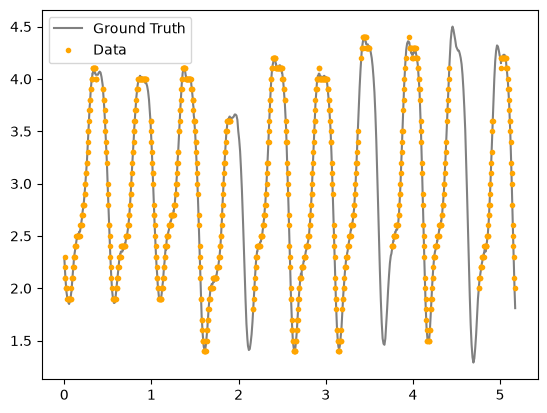

In [4]:
plt.plot(t, y, label="Ground Truth", color="grey")
plt.plot(t, f, '.', label="Data", color="Orange")
plt.legend()

## Kernel Functions
Various parameterised kernel functions and combinations thereof for use in GPs

In [5]:
def d(x1: jax.Array, x2: jax.Array) -> float:
    return jnp.linalg.norm(x1 - x2)

def k_rbf(l: float, lengthscale: float) -> Callable[[jax.Array, jax.Array], float]:
    def kernel(x1, x2):
        sqdist = jnp.sum((x1 - x2)**2)
        return l**2 * jnp.exp(
            -sqdist / (2 * lengthscale**2)
        )
    return kernel

def k_rational_quadratic(l: float, alpha: float, lengthscale: float) -> Callable[[jax.Array, jax.Array], float]:
    return lambda x1, x2: l ** 2 * (1 + d(x1, x2) ** 2 / 2 / alpha / lengthscale ** 2) ** -alpha

def k_periodic(l: float, rho: float, lengthscale: float) -> Callable[[jax.Array, jax.Array], float]:
    return lambda x1, x2: l ** 2 * jnp.exp(-2 * jnp.sin(jnp.pi * d(x1, x2) / rho) ** 2 / lengthscale ** 2)

def k_sum(k1: Callable[[jax.Array, jax.Array], float], k2: Callable[[jax.Array, jax.Array], float]) -> Callable[[jax.Array, jax.Array], float]:
    return lambda x1, x2: k1(x1, x2) + k2(x1, x2)

def k_multiply(k1: Callable[[jax.Array, jax.Array], float], k2: Callable[[jax.Array, jax.Array], float]) -> Callable[[jax.Array, jax.Array], float]:
    return lambda x1, x2: k1(x1, x2) * k2(x1, x2) 

## Mean Functions
Simple parameterised mean functions for use in GPs

In [6]:
def mu_zero() -> Callable[[jax.Array], jax.Array]:
    return lambda x: jnp.zeros((x.shape[0],))

def mu_mean(f: jax.Array) -> Callable[[jax.Array], jax.Array]:
    return mu_constant(jnp.mean(f))

def mu_constant(theta: float) -> Callable[[jax.Array], jax.Array]:
    return lambda x: jnp.full((x.shape[0],), theta)

In [7]:
class GaussianProcess:
    """
    Gaussian Process fit implementation. Assumes the true value y_i is Gaussian
    distributed with mean f(t_i) and standard deviation noise_std.
    """
    def __init__(
        self,
        t: jax.Array,
        f: jax.Array,
        mean_func: Callable[[jax.Array], jax.Array],
        kernel: Callable[[jax.Array, jax.Array], float],
        noise_std: float = 0.1
    ):
        t = jnp.atleast_1d(t)
        self._t = t[:, None] if t.ndim == 1 else t
        self._f = jnp.atleast_1d(f)

        if len(self._t) != len(self._f):
            raise ValueError("Inputs and observations must have the same length")

        self.input_dim = self._t.shape[1]

        self._mean_func = mean_func
        self._kernel = kernel
        self.noise_std = noise_std

        # Precompute various quantities that we need for re-use
        self.K = self._compute_K(self._t, self._t, kernel)
        self.K += noise_std**2 * jnp.eye(len(self._t))
        self.residual = self._f - mean_func(self._t)

        self.cho = jsp.linalg.cho_factor(self.K, lower=True)
        self.alpha = jsp.linalg.cho_solve(self.cho, self.residual)
    
    def predict(self, t: jax.Array) -> tuple[jax.Array, jax.Array]:
        """
        Given positions t, compute the posterior distribution of their
        values, using the whole training dataset.

        Returns a tuple [mean, covariance] 
        """
        t = jnp.atleast_1d(t)
        t = t[:, None] if t.ndim == 1 else t
        K_new = self._compute_K(t, self._t, self._kernel)
        K_ss = self._compute_K(t, t, self._kernel)

        m = self._mean_func(t) + K_new @ self.alpha
        C = K_ss - K_new @ jsp.linalg.cho_solve(self.cho, K_new.T)
        C = (C + C.T) / 2 # ensure C is exactly symmetric

        return m, C

    def predict_sequential(self, t: float) -> tuple[jax.Array, jax.Array]:
        """
        Given a position t, compute the posterior distribution of its
        value, using only the values from the training set that are prior to t.

        Returns a tuple [mean, covariance] 
        """
        if self.input_dim != 1:
            raise RuntimeError("Only supported for 1D input data")

        t_1d = self._t[:, 0]
        n = int(jnp.searchsorted(t_1d, t, 'left'))
        t_causal = t_1d[:n]
        f_causal = self._f[:n]
        L = self._cholesky_for_first_n(n)
        t = jnp.atleast_1d(t)
        residual = f_causal - self._mean_func(t_causal)
        alpha = jsp.linalg.cho_solve((L, True), residual)

        K_new = self._compute_K(t, t_causal, self._kernel)
        K_ss = self._kernel(t, t)

        m = self._mean_func(t) + K_new @ alpha
        C = K_ss - K_new @ jsp.linalg.cho_solve((L, True), K_new.T)  
        C = (C + C.T) / 2
        
        return m, C
    
    def predict_sequential_sliding_window(self, t: float, lookahead: float = 0) -> tuple[jax.Array, jax.Array]:
        """
        Given a position t, compute the posterior distribution of its
        value, using only the values from the training set that are 
        in a 1 day window before t.
        
        Optionally, shift the available training set backwards by
        `lookahead` days to simulate predictions where only data that
        is at least `lookahead` days old is available for training.

        Returns a tuple [mean, covariance] 
        """
        if self.input_dim != 1:
            raise RuntimeError("Only supported for 1D input data")

        window = 1 # 1 day sliding window - hardcoded for now...
        t_1d = self._t[:, 0]

        n = int(jnp.searchsorted(t_1d, t - lookahead, 'left'))
        m = int(jnp.searchsorted(t_1d, t - window - lookahead, 'left'))
        t_causal = t_1d[m:n]
        f_causal = self._f[m:n]

        if m == 0:
            L = self._cholesky_for_first_n(n)
        else:
            K = self.K[m:n, m:n]
            L = jnp.linalg.cholesky(K)
        t = jnp.atleast_1d(t)
        residual = f_causal - self._mean_func(t_causal)
        alpha = jsp.linalg.cho_solve((L, True), residual)

        K_new = self._compute_K(t, t_causal, self._kernel)
        K_ss = self._kernel(t, t)

        m = self._mean_func(t) + K_new @ alpha
        C = K_ss - K_new @ jsp.linalg.cho_solve((L, True), K_new.T)  
        C = (C + C.T) / 2
        
        return m, C

    @functools.cache
    def _cholesky_for_first_n(self, n: int) -> jax.Array:
        """
        Cached implementation of cholesky decomposition for the first
        n training points
        """
        if n <= 5:
            # for small n, compute directly
            K = self.K[:n, :n]
            L = jnp.linalg.cholesky(K)
            return L
        
        prev_L = self._cholesky_for_first_n(n-1)
        return self.update_cholesky(prev_L)

    def update_cholesky(self, L: jax.Array) -> jax.Array:
        """
        Update the Cholesky factor after adding one observation.

        Parameters
        ----------
        L : (n, n) array
            Lower triangular Cholesky factor of the
            existing noisy covariance matrix.

        Returns
        -------
        L_new : (n+1, n+1) array
            Updated lower triangular Cholesky factor.
        """

        n = L.shape[0]

        # Covariance between new and existing inputs
        k = self.K[:n, n]

        # Variance of new noisy observation
        c = self.K[n, n]

        # Solve L @ v = k
        v = jsp.linalg.solve_triangular(
            L, k, lower=True
        )

        # New diagonal entry
        d = jnp.sqrt(c - v @ v)

        L_new = jnp.zeros((n + 1, n + 1))
        L_new = L_new.at[:n, :n].set(L)
        L_new = L_new.at[n, :n].set(v)
        L_new = L_new.at[n, n].set(d)

        return L_new

    def log_likelihood(self):
        """
        Return the log likelihood of the training data given the
        model.
        """
        N = len(self._t)

        return (
            -0.5 * self.residual @ self.alpha
            - jnp.sum(jnp.log(jnp.diag(self.cho[0])))
            - 0.5 * N * jnp.log(2 * np.pi)
        )

    def predictive_log_likelihood(self, t_test: jax.Array, y_test: jax.Array):
        """
        Return the log likelihood of the provided data given the
        model.
        """
        if len(t_test) != len(y_test):
            raise ValueError("t_test and y_test should have the same length")

        n = len(y_test)
        m, C = self.predict(t_test)

        # Include observation noise
        C_y = C + self.noise_std**2 * jnp.eye(n)

        L, _ = jsp.linalg.cho_factor(C_y, True)
        residual = y_test - m

        alpha = jsp.linalg.cho_solve(
            (L, True), residual
        )

        return (
            -0.5 * residual @ alpha
            - jnp.sum(jnp.log(jnp.diag(L)))
            - 0.5 * n * jnp.log(2 * jnp.pi)
        )


    def add_observation(self, t_new: jax.Array, f_new: float) -> None:
        """
        Add a new observation (t_new, f_new) at an arbitrary position,
        updating the GP without recomputing the full Cholesky factor.
        """
        t_new = jnp.asarray(t_new).reshape(1, self.input_dim)
        f_new = jnp.asarray(f_new).reshape(1)

        k = self._compute_K(self._t, t_new, self._kernel).ravel()
        c = self._compute_K(t_new, t_new, self._kernel)[0, 0]
        c += self.noise_std**2

        n = len(self._t)
        K_new = jnp.zeros((n + 1, n + 1))
        K_new = K_new.at[:n, :n].set(self.K)
        K_new = K_new.at[:n, n].set(k)
        K_new = K_new.at[n, :n].set(k)
        K_new = K_new.at[n, n].set(c)

        self._t = jnp.concatenate([self._t, t_new], axis=0)
        self._f = jnp.concatenate([self._f, f_new])
        self.K = K_new

        self.cho = jsp.linalg.cho_factor(self.K, lower=True)
        self.residual = (
            self._f - jnp.asarray(self._mean_func(self._t)).reshape(-1)
        )
        self.alpha = jsp.linalg.cho_solve(self.cho, self.residual)

        self._cholesky_for_first_n.cache_clear()

    @staticmethod
    def _compute_K(t1: jax.Array, t2: jax.Array, kernel) -> jax.Array:
        t1 = jnp.atleast_1d(t1)
        t2 = jnp.atleast_1d(t2)

        return jax.vmap(
            lambda x1: jax.vmap(
                lambda x2: kernel(x1, x2)
            )(t2)
        )(t1)

    

In [8]:

# k = k_rbf(3, 0.5)
k = k_periodic(
    l=3,
    rho=12.42 / 24,
    lengthscale=0.5
)
GP_zeromean_periodic = GaussianProcess(t_clean, f_clean, mu_zero(), k)

In [9]:
def evaluate(gp: GaussianProcess):
    m, C = gp.predict(t)
    std = jnp.sqrt(jnp.diag(C))

    rmse = jnp.linalg.norm(y - m) / math.sqrt(len(y))
    print(f"RMSE = {rmse}")
    predictive_log_likelihood = gp.predictive_log_likelihood(t, y)
    print(f"Predictive Log Likelihood = {predictive_log_likelihood}")

    # Plot predicted mean
    plt.plot(t, y, label="Ground Truth", color="grey")
    plt.plot(t, f, '.', label="Data", color="Orange")
    plt.plot(t, m, label="Predicted mean", color="blue")

    # Plot ±2 standard deviations
    plt.fill_between(
        t,
        m - 2 * std,
        m + 2 * std,
        color="blue",
        alpha=0.2,
        label="±2 standard deviations"
    )

    plt.xlabel("Time (days)")
    plt.ylabel("Predicted value")
    plt.legend()
    plt.grid(alpha=0.3)

RMSE = 0.20052635940005978
Predictive Log Likelihood = -754.3123182904287


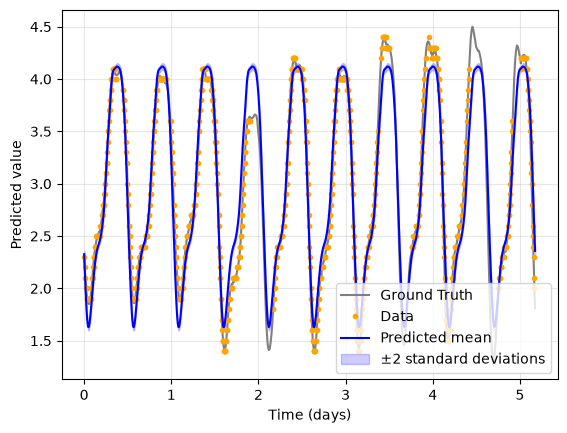

In [10]:
evaluate(GP_zeromean_periodic)

## Maximum likelihood estimation of GP parameters

In [11]:
def loss_mle(
    mu_factory: Callable[[jax.Array], Callable[[jax.Array], jax.Array]],
    k_factory: Callable[[jax.Array], Callable[[jax.Array, jax.Array], float]]
    ) -> Callable[[jax.Array], float]:
    """
    Returns a function which calculates the NLL loss for a GP trained with the given
    hyperparameters
    """
    return lambda hypers: -GaussianProcess(t_clean, f_clean, mu_factory(hypers), k_factory(hypers)).log_likelihood()


In [12]:
def optimise_hypers(
    loss_fun: Callable,
    mu_factory: Callable[[jax.Array], Callable[[jax.Array], jax.Array]],
    k_factory: Callable[[jax.Array], Callable[[jax.Array, jax.Array], float]]
    ) -> jax.Array:
    """
    Given a loss function, optimise hyperparameters of the mu and k functions.
    Note that this is not quite generic yet, the inital guess and optimisation
    constraints are hardcoded here....
    Note also that we use Jax autograd throughout to improve the convergence
    speed of the L-BFGS-B optimisation routine.
    """
    loss_and_grad = jax.jit(jax.value_and_grad(loss_fun(mu_factory, k_factory)))
    result = scp.optimize.minimize(loss_and_grad, [0, 1, 1, 12.42 / 24, 1], method="L-BFGS-B", jac=True, bounds=[
        (None, None),
        (0.001, None),
        (0.001, None),
        (0.001, None),
        (0.001, None),
    ])
    best_hypers = result.x
    print(best_hypers)
    return best_hypers

In [13]:
mu_factory = lambda hypers: mu_constant(hypers[0])
k_factory = lambda hypers: k_multiply(k_rbf(hypers[1], hypers[2]), k_periodic(hypers[1], hypers[3], hypers[4]))
best_mle_hypers = optimise_hypers(loss_mle, mu_factory, k_factory)
gp_mle = GaussianProcess(t_clean, f_clean, mu_factory(best_mle_hypers), k_factory(best_mle_hypers))

[2.93479181 0.95106188 0.61092544 0.51835291 1.05551975]


RMSE = 0.031373867972965874
Predictive Log Likelihood = 1667.2468534442992


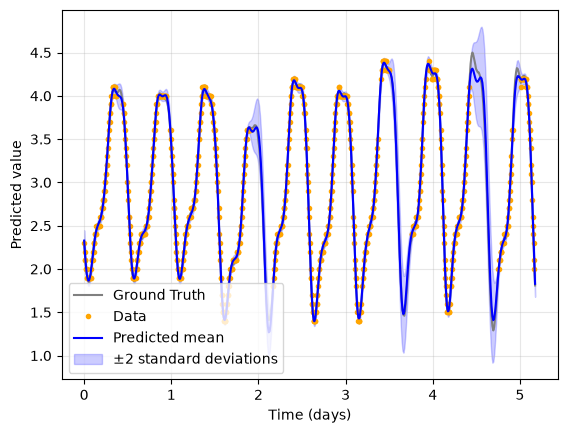

In [14]:
evaluate(gp_mle)

## Maximum a posteriori estimation of GP parameters

In [15]:
def loss_map(
    mu_factory: Callable[[jax.Array], Callable[[jax.Array], jax.Array]],
    k_factory: Callable[[jax.Array], Callable[[jax.Array, jax.Array], float]],
    prior_func: Callable[[jax.Array], float]
    ) -> Callable[[jax.Array], float]:
    return lambda hypers: -GaussianProcess(t_clean, f_clean, mu_factory(hypers), k_factory(hypers)).log_likelihood() - prior_func(hypers)

In [16]:
def hyper_prior(hypers: jax.Array) -> float:
    """
    Simple prior over hyperparameters
    """
    mu, l, lengthscale_rbf, rho, lengthscale_periodic = hypers
    return (
        jsp.stats.norm.logpdf(mu, 3, 2) +
        jsp.stats.norm.logpdf(l, 3, 2) +
        jsp.stats.norm.logpdf(lengthscale_rbf, 2, 2) +
        jsp.stats.norm.logpdf(rho, 1, 1) +
        jsp.stats.norm.logpdf(lengthscale_periodic, 2, 2)
    )


best_map_hypers = optimise_hypers(lambda x, y: loss_map(x, y, hyper_prior), mu_factory, k_factory)
gp_map = GaussianProcess(t_clean, f_clean, mu_factory(best_map_hypers), k_factory(best_map_hypers))

[2.93584976 0.95514274 0.61208562 0.51835452 1.05983282]


RMSE = 0.031423059702946246
Predictive Log Likelihood = 1667.2133876354123


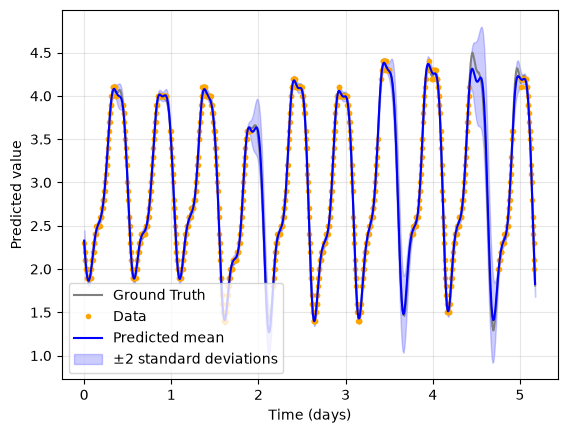

In [17]:
evaluate(gp_map)

## Sequential Prediction of Data

In [18]:
def evaluate_sequential(gp: GaussianProcess):
    n = 500 # runs slowly for n too high, even with optimisations...
    results = [gp.predict_sequential(float(x)) for x in t[:n]]
    m = np.array([tpl[0].squeeze() for tpl in results])
    std = np.array([math.sqrt(tpl[1].squeeze()) for tpl in results])

    rmse = jnp.linalg.norm(y[:n] - m) / math.sqrt(n)
    print(f"RMSE = {rmse}")

    # Plot predicted mean
    plt.plot(t[:n], y[:n], label="Ground Truth", color="grey")
    plt.plot(t[:n], f[:n], '.', label="Data", color="Orange")
    plt.plot(t[:n], m, label="Predicted mean", color="blue")

    # Plot ±2 standard deviations
    plt.fill_between(
        t[:n],
        m - 2 * std,
        m + 2 * std,
        color="blue",
        alpha=0.2,
        label="±2 standard deviations"
    )

    plt.xlabel("Time (days)")
    plt.ylabel("Predicted value")
    plt.legend()
    plt.grid(alpha=0.3)

RMSE = 0.09038557110022408


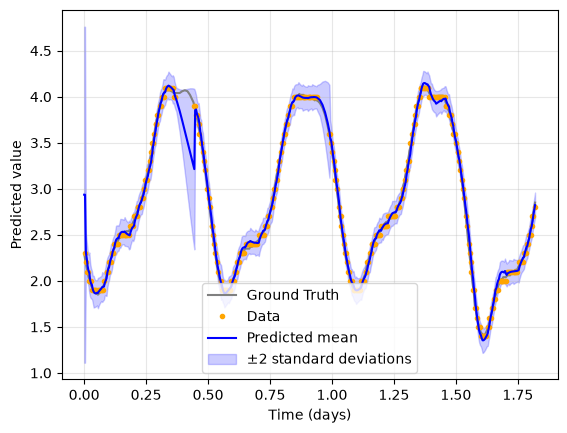

In [19]:
evaluate_sequential(gp_map)

In [20]:
def evaluate_sequential_sliding_window(gp: GaussianProcess):
    results = [gp.predict_sequential_sliding_window(float(x)) for x in t]
    m = np.array([tpl[0].squeeze() for tpl in results])
    std = np.array([math.sqrt(tpl[1].squeeze()) for tpl in results])

    rmse = jnp.linalg.norm(y - m) / math.sqrt(len(y))
    print(f"RMSE = {rmse}")

    # Plot predicted mean
    plt.plot(t, y, label="Ground Truth", color="grey")
    plt.plot(t, f, '.', label="Data", color="Orange")
    plt.plot(t, m, label="Predicted mean", color="blue")

    # Plot ±2 standard deviations
    plt.fill_between(
        t,
        m - 2 * std,
        m + 2 * std,
        color="blue",
        alpha=0.2,
        label="±2 standard deviations"
    )

    plt.xlabel("Time (days)")
    plt.ylabel("Predicted value")
    plt.legend()
    plt.grid(alpha=0.3)

RMSE = 0.12185162113635668


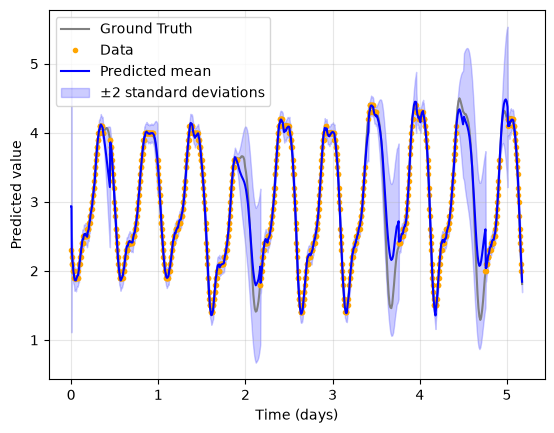

In [21]:
evaluate_sequential_sliding_window(gp_map)

## Lookahead

In [22]:
def format_timedelta(td):
    seconds = td.total_seconds()
    if seconds >= 86400:
        return f"{seconds / 86400:g} days"
    if seconds >= 3600:
        return f"{seconds / 3600:g} hours"
    if seconds >= 60:
        return f"{seconds / 60:g} mins"
    return f"{seconds:g} secs"

def evaluate_sequential_sliding_window_lookahead(gp: GaussianProcess, lookahead_td: datetime.timedelta):
    lookahead = lookahead_td.total_seconds() / 86400
    results = [gp.predict_sequential_sliding_window(float(x), lookahead) for x in t]
    m = np.array([tpl[0].squeeze() for tpl in results])
    std = np.array([math.sqrt(tpl[1].squeeze()) for tpl in results])
    rmse = jnp.linalg.norm(y - m) / math.sqrt(len(y))
    print(f"RMSE = {rmse}")

    # Plot predicted mean
    plt.figure()
    plt.plot(t, y, label="Ground Truth", color="grey")
    plt.plot(t, f, '.', label="Data", color="Orange")
    plt.plot(t, m, label="Predicted mean", color="blue")

    # Plot ±2 standard deviations
    plt.fill_between(
        t,
        m - 2 * std,
        m + 2 * std,
        color="blue",
        alpha=0.2,
        label="±2 standard deviations"
    )

    plt.xlabel("Time (days)")
    plt.ylabel(f"Predicted value")
    plt.title(f"{format_timedelta(lookahead_td)} lookahead")
    plt.legend()
    plt.grid(alpha=0.3)
    return rmse

RMSE = 0.12185162113635668
RMSE = 0.13866872777892084
RMSE = 0.18047457354537266
RMSE = 0.26110191636328867
RMSE = 0.40690795689244397
RMSE = 0.4881992752099209
RMSE = 0.5525648748765246
RMSE = 0.5368335971578232
RMSE = 0.7452990145565703


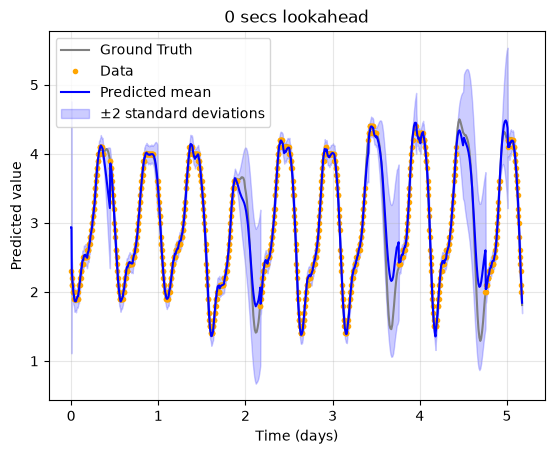

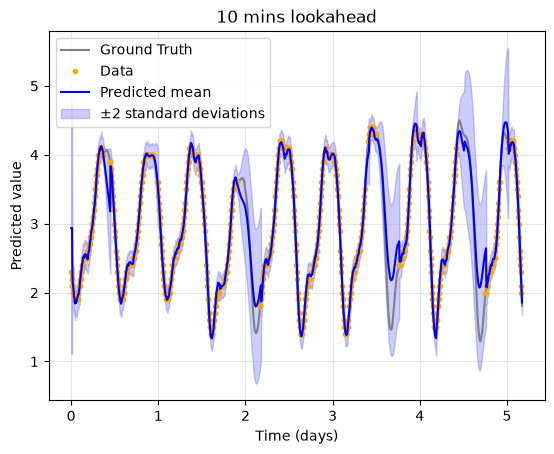

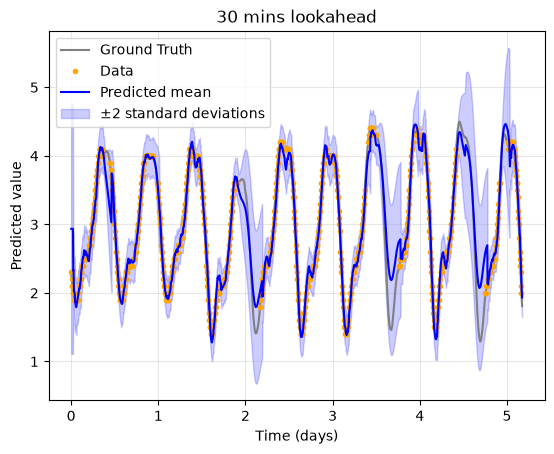

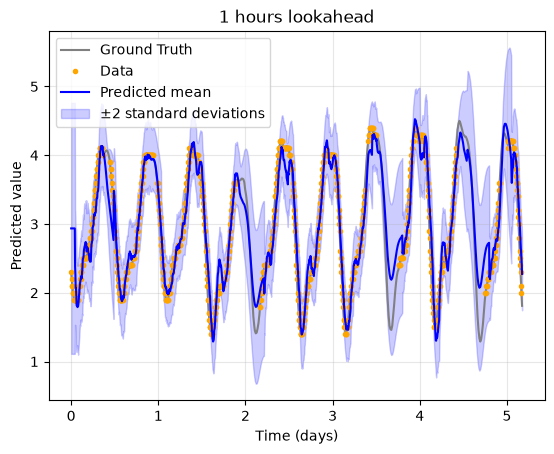

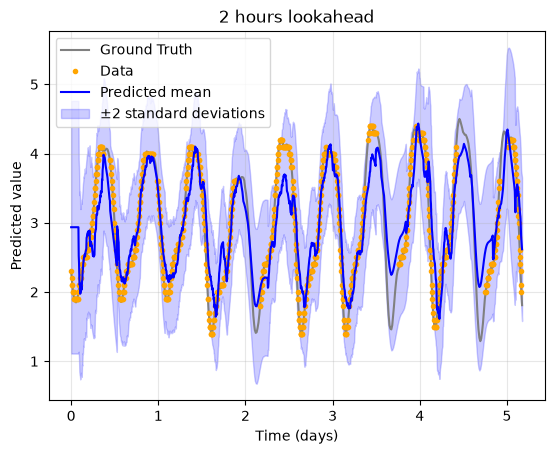

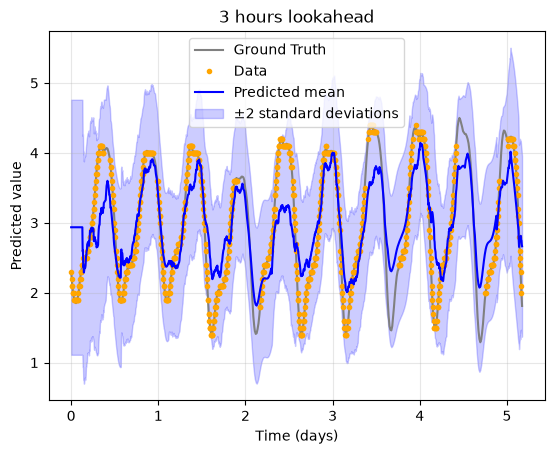

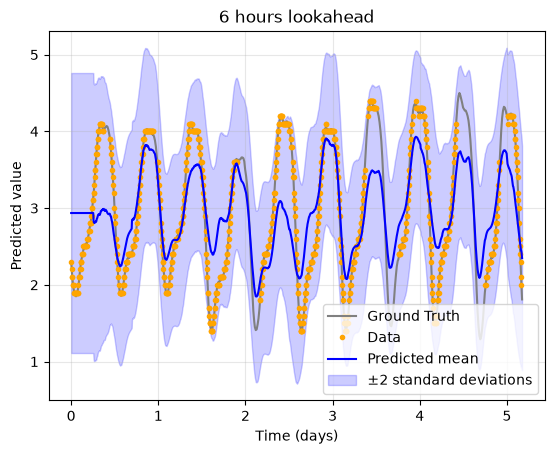

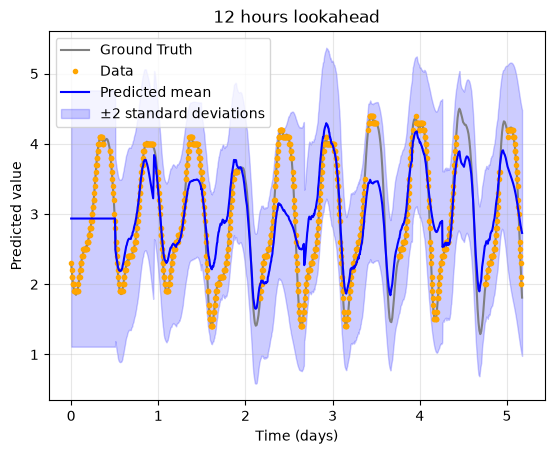

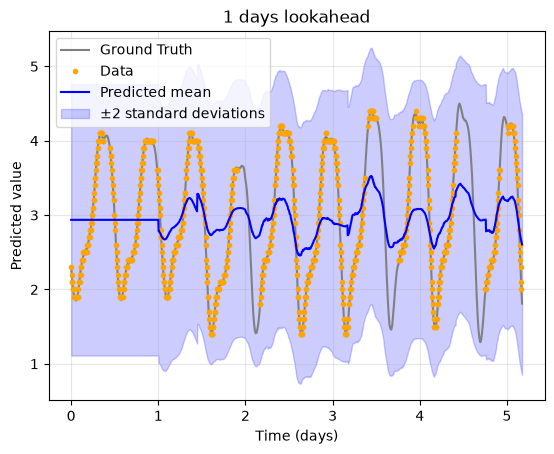

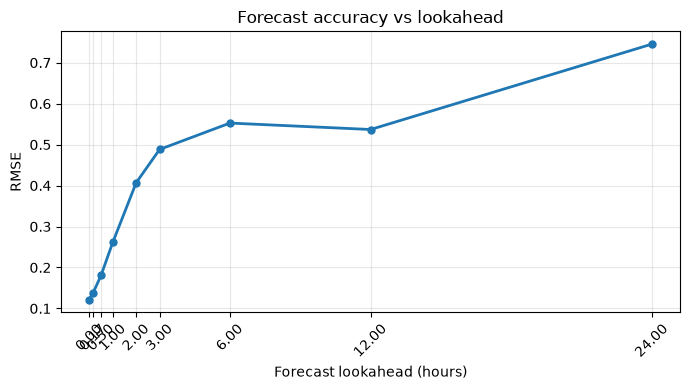

In [23]:
rmse_values = []

lookaheads = [datetime.timedelta(), datetime.timedelta(minutes=10), datetime.timedelta(minutes=30), datetime.timedelta(hours=1), datetime.timedelta(hours=2), datetime.timedelta(hours=3), datetime.timedelta(hours=6), datetime.timedelta(hours=12), datetime.timedelta(days=1)]
lookaheads_hours = [l.total_seconds() / 60 / 60 for l in lookaheads]
for lookahead in lookaheads:
    rmse = evaluate_sequential_sliding_window_lookahead(gp_map, lookahead)
    rmse_values.append(rmse)

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    lookaheads_hours,
    rmse_values,
    "o-",
    color="tab:blue",
    linewidth=2,
    markersize=5,
)

ax.set_xlabel("Forecast lookahead (hours)")
ax.set_ylabel("RMSE")
ax.set_title("Forecast accuracy vs lookahead")
ax.set_xticks(lookaheads_hours)
ax.tick_params(axis="x", labelrotation=45)
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

## Bayesian Optimisation of GP Model Parameters

In [24]:
def optimise_hypers_bayes(
    loss_fun: Callable,
    mu_factory: Callable[[jax.Array], Callable[[jax.Array], jax.Array]],
    k_factory: Callable[[jax.Array], Callable[[jax.Array, jax.Array], float]],
    seed: int = 42
) -> jax.Array:
    """
    Bayesian optimisation of GP hyperparameters using a second GP
    as a surrogate model and Expected Improvement as the acquisition
    function.

    Uses GaussianProcess.add_observation() to update the surrogate
    incrementally after each objective evaluation.
    """
    bounds = np.asarray([
            (-2.0, 8.0),    # mu
            (0.001, 10.0),  # l
            (0.001, 10.0),  # lengthscale_rbf
            (0.01, 2.0),    # rho (period)
            (0.001, 10.0),  # lengthscale_periodic
        ], dtype=float)
    lower, upper = bounds[:, 0], bounds[:, 1]
    dim = len(bounds)

    objective = jax.jit(loss_fun(mu_factory, k_factory))

    # Work in the normalised hyperparameter space [0, 1]^dim
    def evaluate(x):
        hypers = lower + x * (upper - lower)
        return float(objective(jnp.asarray(hypers)))

    # Surrogate GP kernel, defined over hyperparameter space
    surrogate_kernel = k_rbf(1.0, 0.2)
    surrogate_mean = mu_constant(1.0)

    sampler = scp.stats.qmc.Sobol(d=dim, rng=seed)

    # generate some initial data points
    X = sampler.random_base2(2)
    Y = np.array([evaluate(x) for x in X])
    if not np.all(np.isfinite(Y)):
        raise ValueError(
            f"Non-finite initial objective values: {Y}"
        )

    y_mean = Y.mean()
    y_std = max(Y.std(), 1e-8)
    y_min = float(Y.min())
    x_best = X[np.argmin(Y)].copy()

    surrogate = GaussianProcess(
        jnp.asarray(X),
        jnp.asarray((Y - y_mean) / y_std),
        surrogate_mean,
        surrogate_kernel,
        noise_std=1e-3,
    )

    # Expected Improvement acquisition function
    def batched_negative_ei(X):
        mu, C = surrogate.predict(X)

        sigma = jnp.sqrt(jnp.maximum(jnp.diag(C), 1e-12))
        improvement = (y_min - y_mean) / y_std - mu
        z = improvement / sigma

        return -improvement * jsp.stats.norm.cdf(z) - sigma * jsp.stats.norm.pdf(z)

    batched_nei_grad = jax.grad(lambda X: jnp.sum(batched_negative_ei(X)))

    def gradient_descent(X, n_steps=5, lr=0.05):
        for _ in range(n_steps):
            X = jnp.clip(X - lr * batched_nei_grad(X), 0.0, 1.0)

        values = batched_negative_ei(X)
        return X, values


    # Sequential Bayesian optimisation
    for i in range(120):
        # Evaluate EI at random candidate locations
        candidates = sampler.random(100)
        ei_values = batched_negative_ei(candidates)
        
        # Select the 10 most promising candidates
        starts = candidates[jnp.argsort(ei_values)[:10]]

        # Refine all candidates simultaneously using gradient descent
        # In practice this is much quicker compared to full optimisation
        # and allows more samples to be made for this problem setting
        refined_x, refined_values = gradient_descent(starts)

        x_next = refined_x[jnp.argmin(refined_values)]

        # Evaluate the true objective
        y_next = evaluate(x_next)

        if not np.isfinite(y_next):
            raise ValueError(f"Objective evaluation is not finite: {y_next}")

        if y_next < y_min:
            y_min = y_next
            x_best = x_next

        # Incrementally update the surrogate GP
        surrogate.add_observation(
            x_next,
            (y_next - y_mean) / y_std,
        )

        if i == 0 or (i+1) % 10 == 0:
            print(f"Iteration {i+1}: best LL = {-y_min:.4f}; current LL = {-y_next:.4f}")

    best_hypers = lower + x_best * (upper - lower)
    print("Best hyperparameters:", best_hypers)
    return jnp.asarray(best_hypers)


In [25]:
best_hypers_bayes = optimise_hypers_bayes(
    loss_mle,
    mu_factory,
    k_factory,
)

Iteration 1: best LL = -1877.1095; current LL = -1877.1095
Iteration 10: best LL = 842.9796; current LL = -2284.3173
Iteration 20: best LL = 842.9796; current LL = -257.0717
Iteration 30: best LL = 842.9796; current LL = -2711.8029
Iteration 40: best LL = 842.9796; current LL = -1283.0671
Iteration 50: best LL = 889.4221; current LL = -1390.7556
Iteration 60: best LL = 889.4221; current LL = 550.9841
Iteration 70: best LL = 889.4221; current LL = -4237.1626
Iteration 80: best LL = 889.4221; current LL = -4591.1574
Iteration 90: best LL = 889.4221; current LL = 646.7655
Iteration 100: best LL = 889.4221; current LL = 342.5593
Iteration 110: best LL = 889.4221; current LL = -325.9874
Iteration 120: best LL = 902.4259; current LL = 753.6712
Best hyperparameters: [5.221141   5.12031323 2.47397491 1.0231394  0.73668231]


RMSE = 0.04371224882618099
Predictive Log Likelihood = 1664.218413369143


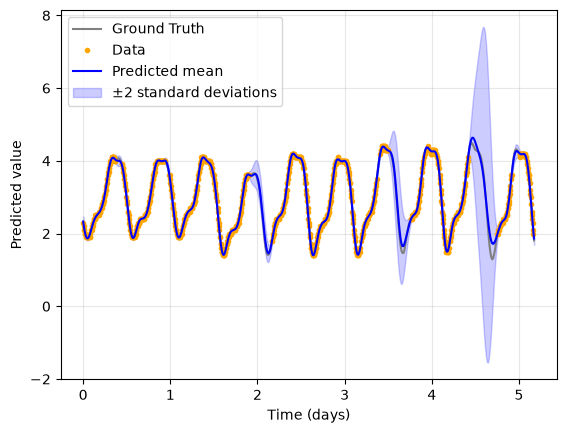

In [26]:
gp_bayes = GaussianProcess(t_clean, f_clean, mu_factory(best_hypers_bayes), k_factory(best_hypers_bayes))
evaluate(gp_bayes)

MLE             RMSE = 0.03137, LL = 999.61485
MAP             RMSE = 0.03142, LL = 999.61308
Bayesian Opt.   RMSE = 0.04371, LL = 902.42586


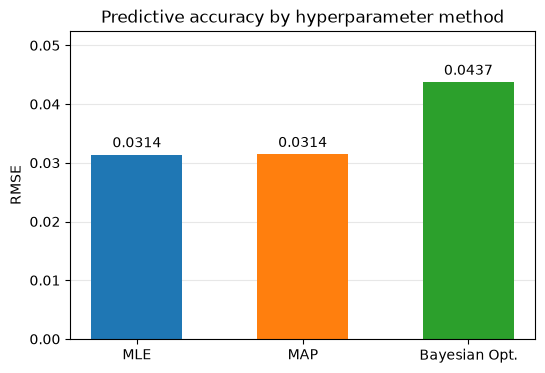

In [27]:
models = {
    "MLE": gp_mle,
    "MAP": gp_map,
    "Bayesian Opt.": gp_bayes,
}

rmse_values = []
ll_values = []

y_true = np.asarray(y).reshape(-1)

for name, gp in models.items():
    mean, _ = gp.predict(t)

    mean = np.asarray(mean).reshape(-1)

    rmse = np.sqrt(np.mean((y_true - mean)**2))
    ll = float(gp.log_likelihood())

    rmse_values.append(rmse)
    ll_values.append(ll)

    print(f"{name:15s} RMSE = {rmse:.5f}, LL = {ll:.5f}")

fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(
    list(models.keys()),
    rmse_values,
    color=["tab:blue", "tab:orange", "tab:green"],
    width=0.55,
)

ax.bar_label(bars, fmt="%.4f", padding=3)

ax.set_ylabel("RMSE")
ax.set_title("Predictive accuracy by hyperparameter method")
ax.set_ylim(0, max(rmse_values) * 1.2)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.show()
